# Normative Model (Structural)

Train a quantile regression MLP that predicts the 10th, 50th and 90th percentiles of the total gray matter volume (`TotalGrayVol`) given Age and Sex.

Input data: `../data/processed/abide_structural_cleaned.csv` (from `preprocessing_structural.ipynb`)

In [1]:
# Import
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader, random_split
import os
import json
import random
import copy

In [2]:
# Random seed for reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Device: GPU (cuda), Apple Silicon (mps) or cpu
device = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
print(f"Device: {device}")
print(f"PyTorch version: {torch.__version__}")

Device: mps
PyTorch version: 2.5.1


## Load Data

Loading the preprocessed dataset and the scaling parameters (used later to transform predictions back to mm³).

In [3]:
# Preprocessed dataset
df = pd.read_csv("../data/processed/abide_structural_cleaned.csv")
print(f"Total samples: {len(df)}")

# Scaling parameters
with open("../data/processed/scaling_params_structural.json", "r") as f:
    scaling_params = json.load(f)

age_mean = scaling_params['age_mean']
age_std = scaling_params['age_std']
vol_mean = scaling_params['vol_mean']
vol_std = scaling_params['vol_std']
print(scaling_params)

df.head()

Total samples: 477
{'age_mean': 16.95909895178197, 'age_std': 7.32014240993593, 'vol_mean': 726986.6218631573, 'vol_std': 77565.06628857981}


,FILE_ID,SITE_ID,AGE_AT_SCAN,SEX,TotalGrayVol,IntraCranialVol,Left-Hippocampus,Right-Hippocampus,Hippocampus,Age_scaled,TotalGrayVol_scaled
0,Pitt_0050030,PITT,25.12,0,706581.114475,1.157527e+06,3982.0,4061.0,8043.0,1.114856,-0.263076
1,Pitt_0050031,PITT,12.92,0,783889.187268,1.208583e+06,4235.0,4477.0,8712.0,-0.551779,0.733611
2,Pitt_0050032,PITT,19.80,0,730058.146235,1.206391e+06,4475.0,4598.0,9073.0,0.388094,0.039599
3,Pitt_0050033,PITT,12.15,0,720818.859215,1.059904e+06,4445.0,4379.0,8824.0,-0.656968,-0.079517
4,Pitt_0050034,PITT,14.77,0,729693.739442,1.094946e+06,4074.0,4394.0,8468.0,-0.299051,0.034901


**Dataset and DataLoader**

Converting the inputs (`Age_scaled`, `SEX`) and target (`TotalGrayVol_scaled`) into a PyTorch `TensorDataset`, and splitting the data into training (70%), validation (15%) and testing (15%) sets.

In [4]:
# Inputs and target as tensors
X = torch.tensor(df[['Age_scaled', 'SEX']].values, dtype=torch.float32)
y = torch.tensor(df['TotalGrayVol_scaled'].values, dtype=torch.float32).unsqueeze(1)

# call dataset
dataset = TensorDataset(X, y)

# Split data (70/15/15)
generator = torch.Generator().manual_seed(SEED)
train_size = int(0.70 * len(dataset))
val_size = int(0.15 * len(dataset))
test_size = len(dataset) - train_size - val_size

train_dataset, val_dataset, test_dataset = random_split(dataset, [train_size, val_size, test_size], generator=generator)

print(f"Training set size: {len(train_dataset)} samples")
print(f"Validation set size: {len(val_dataset)} samples")
print(f"Test set size: {len(test_dataset)} samples")

# dataloaders
batch_size = 16
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

Training set size: 333 samples
Validation set size: 71 samples
Test set size: 73 samples


## Model

MLP with a shared backbone and three outputs: the 10th, 50th (median) and 90th percentiles.

To avoid quantile crossing (e.g. $q_{10} > q_{50}$), the model predicts the median and two distances, made positive with `F.softplus`:

$$\hat{y}_{10} = \hat{y}_{50} - \text{Softplus}(\Delta_{10}) \qquad \hat{y}_{90} = \hat{y}_{50} + \text{Softplus}(\Delta_{90})$$

So $\hat{y}_{10} \le \hat{y}_{50} \le \hat{y}_{90}$ always.

Where:
* $\Delta_{10}$ and $\Delta_{90}$ are the raw outputs of `head_lower` and `head_upper`. They can be any number (positive or negative).
* $\text{Softplus}(x) = \log(1 + e^x)$ turns any number into a positive one (a smooth version of ReLU).

So $\text{Softplus}(\Delta_{10})$ is the distance from the median down to $q_{10}$, and $\text{Softplus}(\Delta_{90})$ the distance up to $q_{90}$.

In [5]:
class QuantileMLP(nn.Module):
    def __init__(self, in_features=2, hidden_dim=32):
        super().__init__()
        # Shared backbone
        self.backbone = nn.Sequential(
            nn.Linear(in_features, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU()
        )
        # Outputs: median and the two distances
        self.head_q50 = nn.Linear(hidden_dim, 1)
        self.head_lower = nn.Linear(hidden_dim, 1)
        self.head_upper = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        features = self.backbone(x)
        q50 = self.head_q50(features)
        # softplus makes the distances positive
        q10 = q50 - F.softplus(self.head_lower(features))
        q90 = q50 + F.softplus(self.head_upper(features))
        # The output has a shape [batch_size, 3], with columns q10, q50, q90
        return torch.cat([q10, q50, q90], dim=1)

model = QuantileMLP().to(device)
print(model)
print(f"Number of parameters: {sum(p.numel() for p in model.parameters())}")

# check with the first batch from train_loader (untrained model)
batch_X, batch_y = next(iter(train_loader))
with torch.no_grad():
    preds = model(batch_X.to(device))
print(f"Output shape: {preds.shape}")
print(f"First 3 predictions [q10, q50, q90]:\n{preds[:3]}")

QuantileMLP(
  (backbone): Sequential(
    (0): Linear(in_features=2, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=32, bias=True)
    (3): ReLU()
  )
  (head_q50): Linear(in_features=32, out_features=1, bias=True)
  (head_lower): Linear(in_features=32, out_features=1, bias=True)
  (head_upper): Linear(in_features=32, out_features=1, bias=True)
)
Number of parameters: 1251


Output shape: torch.Size([16, 3])


First 3 predictions [q10, q50, q90]:
tensor([[-0.7158,  0.0237,  0.6584],
        [-0.7088,  0.0241,  0.6817],
        [-0.7398, -0.0150,  0.6511]], device='mps:0')


## Pinball Loss

The loss that makes each output learn its quantile. For a quantile $\tau$ (0.10, 0.50 or 0.90), with error $u = y - \hat{y}_{\tau}$:

$$L_{\tau}(u) = \max(\tau \, u, \; (\tau - 1) \, u)$$

* $q_{10}$ ($\tau = 0.10$): predicting too high costs 9 times more than too low, so it moves down until ~10% of subjects are below it.
* $q_{50}$ ($\tau = 0.50$): both errors cost the same, so it learns the median.
* $q_{90}$ ($\tau = 0.90$): predicting too low costs 9 times more, so ~90% of subjects end up below it.

The total loss is the mean over the three quantiles and all subjects.

In [6]:
def pinball_loss(preds, y, quantiles=[0.10, 0.50, 0.90]):
    """
    Mean pinball (quantile) loss over all subjects and quantiles.

    preds: model predictions, shape [batch_size, 3], with columns q10, q50, q90
    y: true TotalGrayVol values (scaled), shape [batch_size, 1]
    quantiles: quantile of each column of preds, in the same order
    Returns: the loss as a single number (tensor)
    """
    tau = torch.tensor(quantiles, device=preds.device)
    # Error of each quantile, y is broadcast to [batch_size, 3]
    u = y - preds
    loss = torch.max(tau * u, (tau - 1) * u)
    return loss.mean()

# check with the first batch from train_loader (untrained model)
with torch.no_grad():
    loss = pinball_loss(model(batch_X.to(device)), batch_y.to(device))
print(f"Loss (untrained model): {loss.item():.4f}")

Loss (untrained model): 0.2737


## Training

Each epoch:
1. **Train:** for each batch, predict, compute the pinball loss, and update the weights (`optimizer.step()`).
2. **Validate:** compute the loss on the validation set, without updating the weights.

The model with the lowest validation loss is kept as the best model.

* `AdamW` with `weight_decay`: keeps the weights small to reduce overfitting.
* `ReduceLROnPlateau`: halves the learning rate when the validation loss stops improving for 12 epochs.

In [7]:
# Training settings
epochs = 300
learning_rate = 1e-3
optimizer = optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=1e-3)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=12)

train_losses = []
val_losses = []
best_val_loss = float('inf')

for epoch in range(epochs):
    # Train
    model.train()
    train_loss = 0.0
    for batch_X, batch_y in train_loader:
        batch_X, batch_y = batch_X.to(device), batch_y.to(device)
        optimizer.zero_grad()                        # reset gradients
        loss = pinball_loss(model(batch_X), batch_y)
        loss.backward()                              # compute gradients
        optimizer.step()                             # update weights
        train_loss += loss.item() * len(batch_X)
    train_losses.append(train_loss / len(train_dataset))

    # Validate
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for batch_X, batch_y in val_loader:
            batch_X, batch_y = batch_X.to(device), batch_y.to(device)
            val_loss += pinball_loss(model(batch_X), batch_y).item() * len(batch_X)
    val_losses.append(val_loss / len(val_dataset))
    scheduler.step(val_losses[-1])                   # adjust learning rate

    # Keep the best model
    if val_losses[-1] < best_val_loss:
        best_val_loss = val_losses[-1]
        best_epoch = epoch + 1
        best_model_state = copy.deepcopy(model.state_dict())

    if (epoch + 1) % 25 == 0:
        current_lr = optimizer.param_groups[0]['lr']
        print(f"Epoch {epoch + 1}/{epochs} | Train loss: {train_losses[-1]:.4f} | Val loss: {val_losses[-1]:.4f} | LR: {current_lr:.6f}")

# Load the best model
model.load_state_dict(best_model_state)
print(f"Best model: epoch {best_epoch}, val loss {best_val_loss:.4f}")

Epoch 25/300 | Train loss: 0.2123 | Val loss: 0.2178 | LR: 0.000500


Epoch 50/300 | Train loss: 0.2112 | Val loss: 0.2193 | LR: 0.000125


Epoch 75/300 | Train loss: 0.2111 | Val loss: 0.2195 | LR: 0.000031


Epoch 100/300 | Train loss: 0.2110 | Val loss: 0.2198 | LR: 0.000008


Epoch 125/300 | Train loss: 0.2110 | Val loss: 0.2198 | LR: 0.000004


...

Epoch 200/300 | Train loss: 0.2110 | Val loss: 0.2198 | LR: 0.000000


Epoch 225/300 | Train loss: 0.2110 | Val loss: 0.2198 | LR: 0.000000


Epoch 250/300 | Train loss: 0.2110 | Val loss: 0.2198 | LR: 0.000000


Epoch 275/300 | Train loss: 0.2110 | Val loss: 0.2198 | LR: 0.000000


Epoch 300/300 | Train loss: 0.2110 | Val loss: 0.2198 | LR: 0.000000
Best model: epoch 9, val loss 0.2156


**Baseline**

Comparing with a baseline that ignores Age and Sex: the same 10th, 50th and 90th percentiles (from the training set) for everyone. If the model learned something, its validation loss should be lower.

In [8]:
# Percentiles of the training targets
y_train = y[train_dataset.indices]
baseline_q = torch.quantile(y_train, torch.tensor([0.10, 0.50, 0.90]))

# Same prediction for every validation subject
y_val = y[val_dataset.indices]
baseline_loss = pinball_loss(baseline_q.repeat(len(y_val), 1), y_val).item()

print(f"Baseline val loss: {baseline_loss:.4f}")
print(f"Model val loss:    {best_val_loss:.4f}")
print(f"Improvement:       {100 * (baseline_loss - best_val_loss) / baseline_loss:.1f}%")

Baseline val loss: 0.2360
Model val loss:    0.2156
Improvement:       8.7%


## Loss Curves

Train and validation loss per epoch. The dashed line is the best epoch (model kept), and the dotted line the baseline.

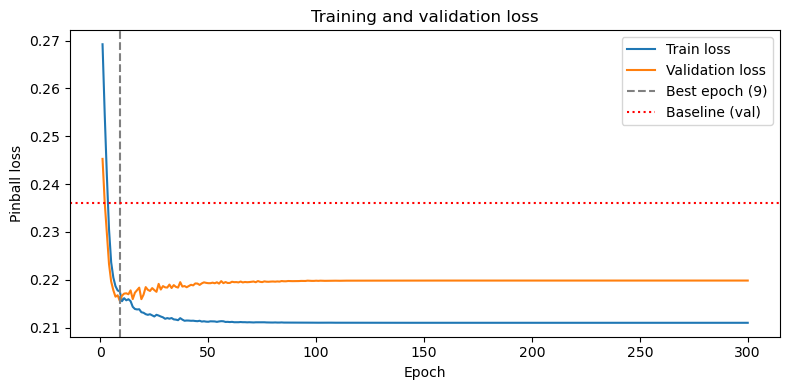

In [9]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, epochs + 1), train_losses, label='Train loss')
plt.plot(range(1, epochs + 1), val_losses, label='Validation loss')
plt.axvline(best_epoch, color='gray', linestyle='--', label=f'Best epoch ({best_epoch})')
plt.axhline(baseline_loss, color='red', linestyle=':', label='Baseline (val)')
plt.xlabel('Epoch')
plt.ylabel('Pinball loss')
plt.title('Training and validation loss')
plt.legend()
plt.tight_layout()
plt.show()

## Test Set Calibration

Checking on the test set (not used during training) whether the quantiles are correct: about 10% of subjects should be below $q_{10}$, 50% below $q_{50}$ and 90% below $q_{90}$. Also the test loss, compared with the baseline.

In [10]:
# Predictions for the test set
y_test = y[test_dataset.indices]
model.eval()
with torch.no_grad():
    test_preds = model(X[test_dataset.indices].to(device)).cpu()

# Test loss vs baseline
test_loss = pinball_loss(test_preds, y_test).item()
baseline_test_loss = pinball_loss(baseline_q.repeat(len(y_test), 1), y_test).item()
print(f"Test loss:          {test_loss:.4f}")
print(f"Baseline test loss: {baseline_test_loss:.4f}")
print(f"Improvement:        {100 * (baseline_test_loss - test_loss) / baseline_test_loss:.1f}%\n")

# Percentage of subjects below each quantile
for i, q in enumerate([10, 50, 90]):
    below = (y_test[:, 0] < test_preds[:, i]).float().mean().item() * 100
    print(f"Below q{q}: {below:.1f}% (expected {q}%)")

# Percentage inside the 10-90 band
inside = ((y_test[:, 0] >= test_preds[:, 0]) & (y_test[:, 0] <= test_preds[:, 2])).float().mean().item() * 100
print(f"Inside q10-q90: {inside:.1f}% (expected 80%)")
print(f"Test subjects: {len(y_test)}")

Test loss:          0.2687
Baseline test loss: 0.2850
Improvement:        5.7%

Below q10: 26.0% (expected 10%)
Below q50: 65.8% (expected 50%)
Below q90: 95.9% (expected 90%)
Inside q10-q90: 69.9% (expected 80%)
Test subjects: 73
